 Підготовка: Прогноз
Перед першим запуском, аналізуючи перший рядок масиву `image`, ми прогнозуємо кольори перших чотирьох пікселів:
* `image[0, 0] = [255, 0, 0]` — **Червоний** (максимум Red, немає Green та Blue).
* `image[0, 1] = [0, 255, 0]` — **Зелений** (максимум Green, немає Red та Blue).
* `image[0, 2] = [0, 0, 255]` — **Синій** (максимум Blue, немає Red та Green).
* `image[0, 3] = [255, 255, 255]` — **Білий** (змішування всіх кольорів на максимумі).

Matplotlib is building the font cache; this may take a moment.


Форма: (3, 4, 3)
Тип: uint8
Кількість пікселів: 12
Кількість числових елементів: 36
RGB до зміни: [ 40  80 200]
RGB після зміни: [128  80 200]


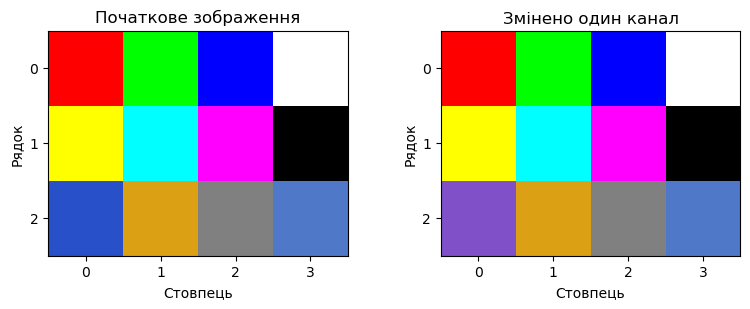

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# У кожному пікселі числа записано в порядку [R, G, B].
image = np.array([
    [[255,   0,   0], [  0, 255,   0], [  0,   0, 255], [255, 255, 255]],
    [[255, 255,   0], [  0, 255, 255], [255,   0, 255], [  0,   0,   0]],
    [[ 40,  80, 200], [220, 160,  20], [128, 128, 128], [ 80, 120, 200]]
], dtype=np.uint8)

def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 3))
    axes = np.atleast_1d(axes)
    for ax, (data, title) in zip(axes, items):
        if data.ndim == 2:
            ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                      interpolation="nearest", origin="upper")
        else:
            ax.imshow(data, interpolation="nearest", origin="upper")
        ax.set_xticks(range(data.shape[1]))
        ax.set_yticks(range(data.shape[0]))
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

# Змінюйте лише параметри нижче. Використовуйте цілі числа.
row = 2
col = 0
channel = 0  # 0 — R, 1 — G, 2 — B
value = 128

if not (0 <= row < image.shape[0] and 0 <= col < image.shape[1]):
    raise ValueError("Індекс пікселя виходить за межі зображення")
if channel not in (0, 1, 2):
    raise ValueError("Індекс каналу має бути 0, 1 або 2")
if not 0 <= value <= 255:
    raise ValueError("Значення каналу має бути від 0 до 255")

changed = image.copy()
changed[row, col, channel] = value

print("Форма:", image.shape)
print("Тип:", image.dtype)
print("Кількість пікселів:", image.shape[0] * image.shape[1])
print("Кількість числових елементів:", image.size)
print("RGB до зміни:", image[row, col])
print("RGB після зміни:", changed[row, col])

show_images([
    (image, "Початкове зображення"),
    (changed, "Змінено один канал")
])

### Таблиця: Зміна одного каналу

*(Усі експерименти проводяться для пікселя `row=2, col=0`, його початковий колір `[ 40,  80, 200]` — синьо-блакитний)*

| Канал | Нове значення | RGB до зміни | Прогноз | RGB після зміни | Що спостерігали |
| :--- | ---: | :--- | :--- | :--- | :--- |
| R (0) | 0 | `[40, 80, 200]` | Піксель стане менш червоним (холоднішим). | `[0, 80, 200]` | Колір став трохи синішим, зник фіолетовий відтінок. |
| R (0) | 128 | `[40, 80, 200]` | З'явиться фіолетовий/рожевий відтінок. | `[128, 80, 200]` | Піксель набув вираженого фіолетового відтінку. |
| R (0) | 255 | `[40, 80, 200]` | Стане яскраво-рожевим/малиновим. | `[255, 80, 200]` | Піксель став яскраво-рожевим (пурпуровим). |
| G (1) | 0 | `[40, 80, 200]` | Зникне зелений, стане темнішим синім. | `[40, 0, 200]` | Піксель став темно-синім із легким фіолетовим тоном. |
| G (1) | 128 | `[40, 80, 200]` | Стане світлішим, більш блакитним. | `[40, 128, 200]` | Колір став світло-блакитним. |
| G (1) | 255 | `[40, 80, 200]` | Стане яскравим ціаном (синьо-зеленим). | `[40, 255, 200]` | Піксель став дуже світлим синьо-зеленим (бірюзовим). |
| B (2) | 0 | `[40, 80, 200]` | Синій зникне, залишиться темно-зелений/коричневий. | `[40, 80, 0]` | Піксель став темно-зеленим (болотним). |
| B (2) | 128 | `[40, 80, 200]` | Синій стане слабшим, колір потьмяніє. | `[40, 80, 128]` | Колір став сіро-синім, менш насиченим. |
| B (2) | 255 | `[40, 80, 200]` | Стане максимально синім/блакитним. | `[40, 80, 255]` | Піксель став дуже яскравим синім. |

### Три матриці каналів і їх перестановка

1. **Прогноз світлих пікселів для матриць каналів:**
   * Світлий на зображенні R: `row=0, col=0` (колір червоний, `R=255`).
   * Світлий на зображенні G: `row=0, col=1` (колір зелений, `G=255`).
   * Світлий на зображенні B: `row=0, col=2` (колір синій, `B=255`).

Матриця R:
 [[255   0   0 255]
 [255   0 255   0]
 [128   0   0 128]]
Матриця G:
 [[  0 255   0 255]
 [255 255   0   0]
 [  0 128   0 128]]
Матриця B:
 [[  0   0 255 255]
 [  0 255 255   0]
 [  0   0 128 128]]
Форми каналів: (3, 4) (3, 4) (3, 4)


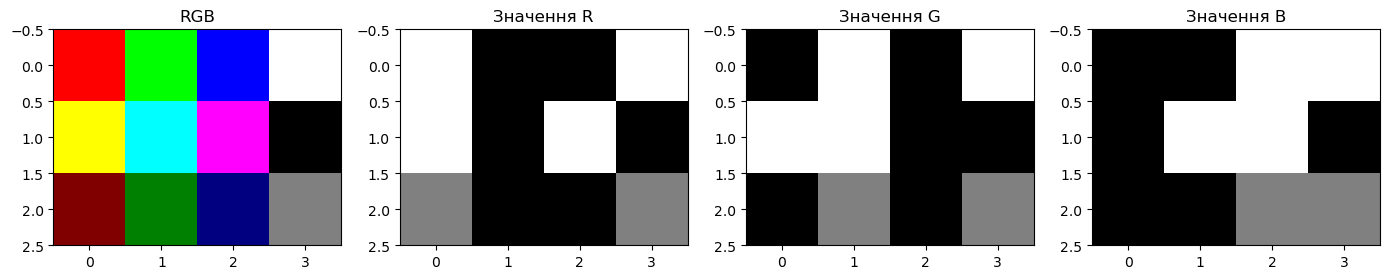

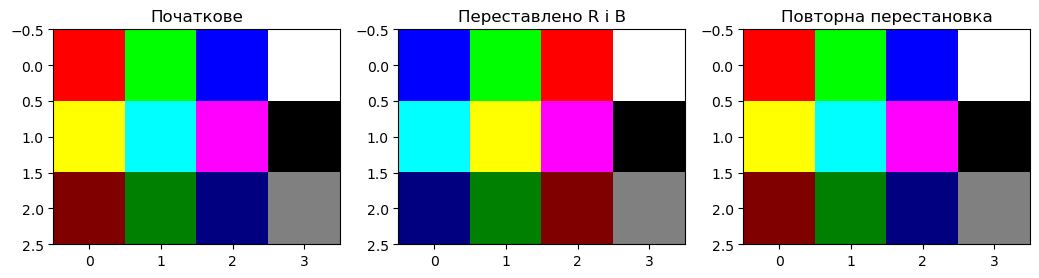

Відновлення точне: True


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Вспомогательная функция отрисовки (добавлена, чтобы не было ошибки NameError)
def show_images(img_list):
    n = len(img_list)
    fig, axes = plt.subplots(1, n, figsize=(3.5 * n, 3))
    if n == 1:
        axes = [axes]
    for ax, item in zip(axes, img_list):
        img, title = item[0], item[1]
        if len(img.shape) == 2:
            ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        else:
            ax.imshow(img, interpolation='nearest')
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

# 1. Создаем матрицу изображения (3x4x3, RGB)
image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255],   [255, 255, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255], [0, 0, 0]],
    [[128, 0, 0],   [0, 128, 0],   [0, 0, 128],   [128, 128, 128]]
], dtype=np.uint8)

# 2. Разделяем изображение на 3 цветовых канала (Red, Green, Blue)
red = image[:, :, 0]
green = image[:, :, 1]
blue = image[:, :, 2]

print("Матриця R:\n", red)
print("Матриця G:\n", green)
print("Матриця B:\n", blue)
print("Форми каналів:", red.shape, green.shape, blue.shape)

# 3. Отрисовываем исходное изображение и каналы
show_images([
    (image, "RGB"),
    (red, "Значення R"),
    (green, "Значення G"),
    (blue, "Значення B")
])

# 4. Меняем порядок каналов (R и B местами) и повторяем перестановку
swapped = image[:, :, [2, 1, 0]]
restored = swapped[:, :, [2, 1, 0]]

# 5. Отрисовываем результаты перестановки
show_images([
    (image, "Початкове"),
    (swapped, "Переставлено R і B"),
    (restored, "Повторна перестановка")
])

print("Відновлення точне:", np.array_equal(image, restored))

In [ ]:
2. **Перестановка R та B для двох пікселів:**
   * Піксель `(0, 0)`: до перестановки `[255, 0, 0]` (червоний), після перестановки `[0, 0, 255]` (став синім).
   * Піксель `(0, 2)`: до перестановки `[0, 0, 255]` (синій), після перестановки `[255, 0, 0]` (став червоним).
3. **Пояснення `np.array_equal`:** Функція повертає `True`. Перестановка каналів є оборотною операцією. Складові кольору не змінюються і не втрачаються, вони просто міняються місцями (індексами). Повторна перестановка повертає значення на їхні початкові місця.

### Два способи перетворення на градації сірого

**Ручні обчислення для двох пікселів:**
* **Чистий червоний (0, 0), RGB `[255, 0, 0]`:**
  * Середнє: `(255 + 0 + 0) / 3 = 85.0`
  * Зважена сума: `0.299 * 255 + 0.587 * 0 + 0.114 * 0 = 76.245` (після округлення `76`).
* **Чистий зелений (0, 1), RGB `[0, 255, 0]`:**
  * Середнє: `(0 + 255 + 0) / 3 = 85.0`
  * Зважена сума: `0.299 * 0 + 0.587 * 255 + 0.114 * 0 = 149.685` (після округлення `150`).
* **Пояснення сірого пікселя `(2, 2)`:** У чистого сірого кольору всі три компоненти RGB рівні (`128, 128, 128`). Тому середнє значення `(128*3)/3` дорівнює `128`. Зважена сума також дорівнює `128`, оскільки сума коефіцієнтів `0.299 + 0.587 + 0.114 = 1.0`, отже `128 * 1.0 = 128`.

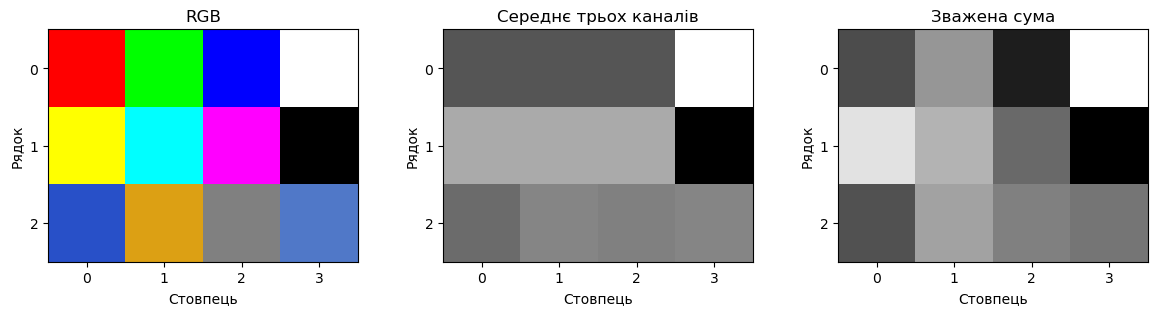

Піксель (0, 0): RGB=[255   0   0], середнє=85, зважене=76
Піксель (0, 1): RGB=[  0 255   0], середнє=85, зважене=150
Піксель (0, 2): RGB=[  0   0 255], середнє=85, зважене=29
Піксель (2, 2): RGB=[128 128 128], середнє=128, зважене=128
RGB shape = (3, 4, 3) dtype = uint8 size = 36 nbytes = 36
Середнє shape = (3, 4) dtype = uint8 size = 12 nbytes = 12
Зважене shape = (3, 4) dtype = uint8 size = 12 nbytes = 12


In [3]:
# Обчислюємо у float, щоб суми не переповнювали uint8.
work = image.astype(np.float64)

gray_mean_float = work.mean(axis=2)
weights = np.array([0.299, 0.587, 0.114])
gray_weighted_float = (work * weights).sum(axis=2)

# Обидва результати зберігаємо в одному типі для порівняння пам'яті.
gray_mean = np.clip(np.rint(gray_mean_float), 0, 255).astype(np.uint8)
gray_weighted = np.clip(np.rint(gray_weighted_float), 0, 255).astype(np.uint8)

show_images([
    (image, "RGB"),
    (gray_mean, "Середнє трьох каналів"),
    (gray_weighted, "Зважена сума")
])

for row, col in [(0, 0), (0, 1), (0, 2), (2, 2)]:
    print(
        f"Піксель ({row}, {col}): RGB={image[row, col]}, "
        f"середнє={gray_mean[row, col]}, "
        f"зважене={gray_weighted[row, col]}"
    )

for name, data in [
    ("RGB", image),
    ("Середнє", gray_mean),
    ("Зважене", gray_weighted)
]:
    print(
        name,
        "shape =", data.shape,
        "dtype =", data.dtype,
        "size =", data.size,
        "nbytes =", data.nbytes
    )

| Піксель | Координати | RGB | Прогноз для середнього | Середнє, після округлення | Прогноз для зваженої суми | Зважена сума, після округлення |
| :--- | :--- | :--- | :--- | :---: | :--- | :---: |
| Чистий червоний | `(0, 0)` | `[255, 0, 0]` | Буде темно-сірим | 85 | Буде ще темнішим за середнє | 76 |
| Чистий зелений | `(0, 1)` | `[0, 255, 0]` | Буде таким же сірим як і червоний | 85 | Буде найсвітлішим з трьох | 150 |
| Чистий синій | `(0, 2)` | `[0, 0, 255]` | Буде таким же сірим як і червоний | 85 | Буде найтемнішим з трьох | 29 |
| Сірий | `(2, 2)` | `[128, 128, 128]`| Залишиться таким самим | 128 | Залишиться таким самим | 128 |

### Форма масивів і обсяг даних

| Зображення | `shape` | `dtype` | Кількість пікселів | `size`: кількість числових елементів | `nbytes`, байтів |
| :--- | :--- | :--- | :---: | :---: | :---: |
| RGB | `(3, 4, 3)` | `uint8` | 12 | 36 | 36 |
| Сіре: просте середнє | `(3, 4)` | `uint8` | 12 | 12 | 12 |
| Сіре: зважена сума | `(3, 4)` | `uint8` | 12 | 12 | 12 |

### Відповіді на питання
1. **Чим відрізняються `image[1, 2]` та `image[1, 2, 0]`?**
   `image[1, 2]` повертає масив із трьох елементів (RGB-вектор) для пікселя у другому рядку та третьому стовпці. Його значення `[255, 0, 255]`. `image[1, 2, 0]` повертає лише одне число — інтенсивність нульового (червоного, R) каналу для цього ж пікселя. Його значення `255`.
2. **Чи є виділення одного каналу перетворенням на градації сірого з використанням усіх трьох каналів?**
   Ні. Виділення одного каналу (наприклад, тільки R) ігнорує дані з двох інших каналів (G і B), тоді як справжнє перетворення на градації сірого використовує інформацію з усіх трьох каналів (через середнє арифметичне або зважену суму), щоб створити єдине значення яскравості.
3. **Чому перестановку R і B можна скасувати, а початкові RGB-значення після перетворення на сіре однозначно відновити не можна?**
   Перестановка зберігає всі значення трьох каналів, просто міняючи їх індекси. Перетворення на сіре є математичною операцією з втратою даних: ми стискаємо 3 числа в 1 (сумуємо їх). Знаючи лише підсумкове сіре значення (наприклад, `85`), неможливо дізнатися, чи було воно утворено червоним `[255, 0, 0]`, зеленим `[0, 255, 0]` чи блакитним `[0, 0, 255]`.
4. **Чи змінилася кількість пікселів після перетворення на сіре? Як змінилися кількість числових елементів та обсяг даних при однаковому `dtype`?**
   Кількість пікселів (фізичних точок зображення `3x4 = 12`) не змінилася. Проте кількість числових елементів (`size`) та загальний обсяг даних (`nbytes`) зменшилися рівно в 3 рази (з 36 до 12). Це сталося тому, що замість масиву з трьох чисел (RGB) кожен піксель тепер описується лише одним числом.

**Висновок:**
Під час виконання завдання було практично досліджено структуру кольорового зображення, яке в пам'яті комп'ютера представлено як тривимірна матриця (RGB-канали). Було доведено, що ізольована зміна значень одного з каналів (наприклад, R, G або B) призводить до прогнозованої зміни колірного відтінку окремого пікселя. Також порівняно методи перетворення кольорового зображення на градації сірого: встановлено, що перетворення згортає три канали в один, зменшуючи обсяг даних втричі, а використання зваженої суми краще відображає візуальну яскравість різних кольорів (наприклад, зелений виглядає світлішим за синій), ніж просте усереднення.